# Model Evaluation

In this notebook, I will evaluate the machine learning models trained in Notebook 4.

The main goal is to compare Logistic Regression and Random Forest using different evaluation metrics.

**Import Libraries**

In [57]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

**Load the Model-Ready Data**

In [58]:
df = pd.read_csv(
    "../data/processed/model_ready_data.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (101766, 21)


**Prepare X and y**

In [59]:
X = df.drop(
    columns=["readmitted_30_days", "patient_nbr"]
)

y = df["readmitted_30_days"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (101766, 19)
y shape: (101766,)


**Create Train/Test Split Again**

In [60]:
from sklearn.model_selection import train_test_split

patient_groups = df["patient_nbr"]

unique_patients = patient_groups.unique()

train_patients, test_patients = train_test_split(
    unique_patients,
    test_size=0.2,
    random_state=42
)

train_mask = patient_groups.isin(train_patients)
test_mask = patient_groups.isin(test_patients)

X_train = X[train_mask]
X_test = X[test_mask]

y_train = y[train_mask]
y_test = y[test_mask]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# We use the same random_state=42, so we recreate the same train/test split from Notebook 4.
# This is important because we want to evaluate the models on the same test data.

Training data: (81477, 19)
Testing data: (20289, 19)


**Load the Saved Models**

In [61]:
import joblib

logistic_model = joblib.load(
    "../models/logistic_regression_model.pkl"
)

random_forest_model = joblib.load(
    "../models/random_forest_model.pkl"
)

print("Models loaded successfully!")

Models loaded successfully!


**Generate Predictions**

In [62]:
logistic_predictions = logistic_model.predict(X_test)

random_forest_predictions = random_forest_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


**Logistic Regression Classification Report**

In [63]:
print("Logistic Regression")
print("----------------------------")

print(
    classification_report(
        y_test,
        logistic_predictions
    )
)

Logistic Regression
----------------------------
              precision    recall  f1-score   support

           0       0.92      0.70      0.79     18120
           1       0.16      0.50      0.25      2169

    accuracy                           0.67     20289
   macro avg       0.54      0.60      0.52     20289
weighted avg       0.84      0.67      0.73     20289



**Explanation**
This gives us several important metrics:
**Precision**
Of the patients predicted as readmitted, how many were actually readmitted?
**Recall**
Of the patients who were actually readmitted, how many did the model identify?
**F1-score**
A balance between precision and recall.
For this project, recall for class 1 is especially important because we want to identify patients who may be readmitted within 30 days.

**Random Forest Classification Report**

In [64]:
print("Random Forest")
print("----------------------------")

print(
    classification_report(
        y_test,
        random_forest_predictions
    )
)

Random Forest
----------------------------
              precision    recall  f1-score   support

           0       0.90      0.98      0.94     18120
           1       0.26      0.06      0.10      2169

    accuracy                           0.88     20289
   macro avg       0.58      0.52      0.52     20289
weighted avg       0.83      0.88      0.85     20289



**Create Model Comparison Table**

In [65]:
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

logistic_precision = precision_score(
    y_test,
    logistic_predictions
)

logistic_recall = recall_score(
    y_test,
    logistic_predictions
)

logistic_f1 = f1_score(
    y_test,
    logistic_predictions
)


random_forest_accuracy = accuracy_score(
    y_test,
    random_forest_predictions
)

random_forest_precision = precision_score(
    y_test,
    random_forest_predictions
)

random_forest_recall = recall_score(
    y_test,
    random_forest_predictions
)

random_forest_f1 = f1_score(
    y_test,
    random_forest_predictions
)


comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        random_forest_accuracy
    ],
    "Precision": [
        logistic_precision,
        random_forest_precision
    ],
    "Recall": [
        logistic_recall,
        random_forest_recall
    ],
    "F1 Score": [
        logistic_f1,
        random_forest_f1
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.674651,0.164446,0.500692,0.247578
1,Random Forest,0.880132,0.255121,0.063163,0.101256


**Round the Results**

In [66]:
comparison.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.675,0.164,0.501,0.248
1,Random Forest,0.880,0.255,0.063,0.101


**Logistic Regression Confusion Matrix**

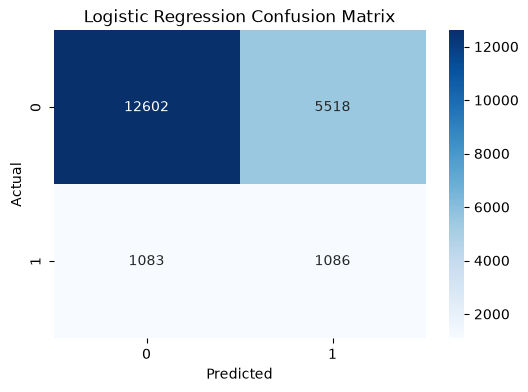

In [67]:
logistic_cm = confusion_matrix(
    y_test,
    logistic_predictions
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()


# For our project, pay special attention to:
# False Negatives
# These are patients who were actually readmitted but the model predicted they would not be.

**Random Forest Confusion Matrix**

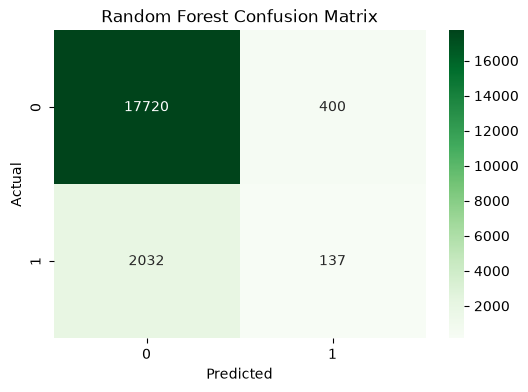

In [68]:
random_forest_cm = confusion_matrix(
    y_test,
    random_forest_predictions
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    random_forest_cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

**ROC-AUC Scores**

In [69]:
logistic_probabilities = logistic_model.predict_proba(
    X_test
)[:, 1]

random_forest_probabilities = random_forest_model.predict_proba(
    X_test
)[:, 1]


logistic_auc = roc_auc_score(
    y_test,
    logistic_probabilities
)

random_forest_auc = roc_auc_score(
    y_test,
    random_forest_probabilities
)

print(
    "Logistic Regression ROC-AUC:",
    round(logistic_auc, 3)
)

print(
    "Random Forest ROC-AUC:",
    round(random_forest_auc, 3)
)

Logistic Regression ROC-AUC: 0.642
Random Forest ROC-AUC: 0.601


In [70]:
# Simple explanation
# ROC-AUC tells us how well the model can distinguish between:
# - 0 → Not readmitted within 30 days
# - 1 → Readmitted within 30 days
# Generally:
# - Around 0.50 → weak
# - Higher values → better ability to distinguish the classes
# For this project, we should consider ROC-AUC along with recall and F1-score.

**Add ROC-AUC to Comparison Table**

In [71]:
comparison["ROC-AUC"] = [
    logistic_auc,
    random_forest_auc
]

comparison.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.675,0.164,0.501,0.248,0.642
1,Random Forest,0.880,0.255,0.063,0.101,0.601


**ROC Curve**

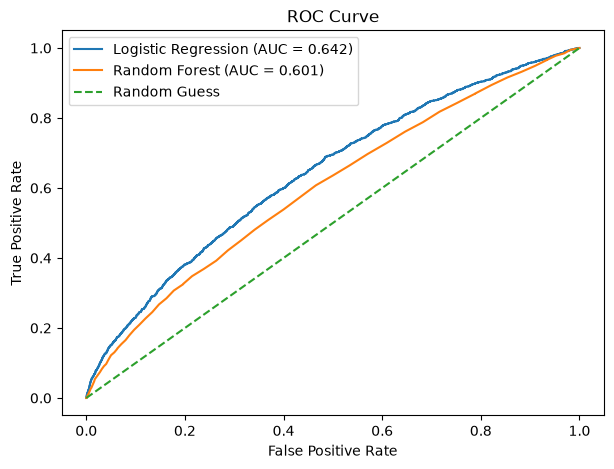

In [72]:
logistic_fpr, logistic_tpr, _ = roc_curve(
    y_test,
    logistic_probabilities
)

random_forest_fpr, random_forest_tpr, _ = roc_curve(
    y_test,
    random_forest_probabilities
)


plt.figure(figsize=(7, 5))

plt.plot(
    logistic_fpr,
    logistic_tpr,
    label=f"Logistic Regression (AUC = {logistic_auc:.3f})"
)

plt.plot(
    random_forest_fpr,
    random_forest_tpr,
    label=f"Random Forest (AUC = {random_forest_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guess"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

# A model whose curve is generally closer to the top-left corner performs better.

**Find the Better Model**

In [73]:
# Instead of automatically choosing based only on accuracy, let's compare F1-score and ROC-AUC.
if random_forest_f1 > logistic_f1:
    better_f1_model = "Random Forest"
else:
    better_f1_model = "Logistic Regression"


if random_forest_auc > logistic_auc:
    better_auc_model = "Random Forest"
else:
    better_auc_model = "Logistic Regression"


print("Better F1-score model:", better_f1_model)
print("Better ROC-AUC model:", better_auc_model)

Better F1-score model: Logistic Regression
Better ROC-AUC model: Logistic Regression


**Random Forest Feature Importance**

In [74]:
rf_preprocessor = random_forest_model.named_steps[
    "preprocessor"
]

rf_model = random_forest_model.named_steps[
    "model"
]

feature_names = (
    rf_preprocessor
    .get_feature_names_out()
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
11,num__total_procedures,0.131074
3,num__num_lab_procedures,0.130618
5,num__num_medications,0.128690
2,num__time_in_hospital,0.086268
4,num__num_procedures,0.060477
9,num__number_diagnoses,0.057374
0,num__admission_type_id,0.041301
10,num__total_previous_visits,0.040379
8,num__number_inpatient,0.037916
1,num__admission_source_id,0.035208


**Plot Top 15 Features**

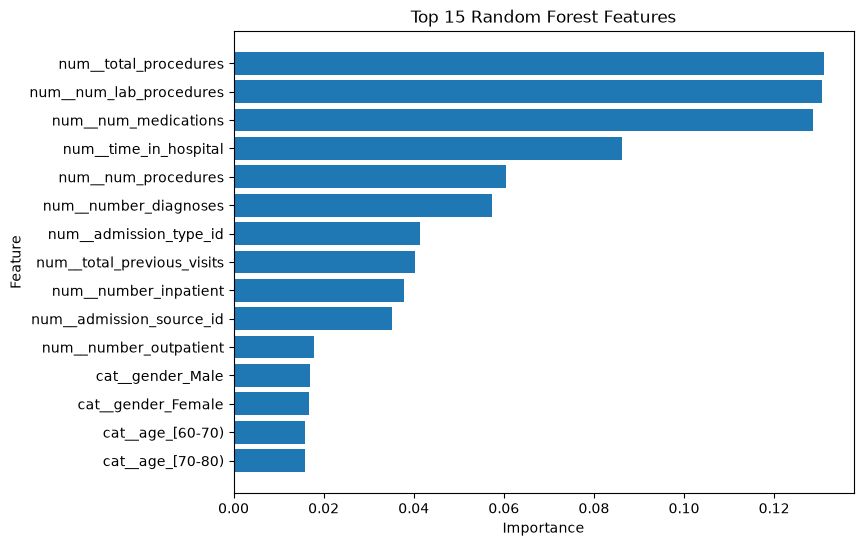

In [75]:
top_features = feature_importance.head(15)

plt.figure(figsize=(8, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    "Top 15 Random Forest Features"
)

plt.show()

**Save Model Comparison**

In [76]:
from pathlib import Path

results_folder = Path("../results")

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

comparison.to_csv(
    results_folder / "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


**Final Results**

In [77]:
print("Final Model Comparison")
print("----------------------------")

print(
    comparison.round(3)
)

Final Model Comparison
----------------------------
                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression     0.675      0.164   0.501     0.248    0.642
1        Random Forest     0.880      0.255   0.063     0.101    0.601


## Conclusion

In this notebook, I evaluated the Logistic Regression and Random Forest models.

I compared the models using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix
- ROC-AUC
- ROC Curve

Because the target variable is imbalanced, I did not rely only on accuracy. I also considered recall, F1-score, and ROC-AUC.

The Random Forest feature importance also helped identify which features were most useful for prediction.

Based on the evaluation results, I selected the model that provided the best overall performance for predicting 30-day hospital readmission.

The model comparison results were saved for future analysis.